In [6]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

from sklearn.cluster import AgglomerativeClustering
from skimage import segmentation, color
from skimage import segmentation


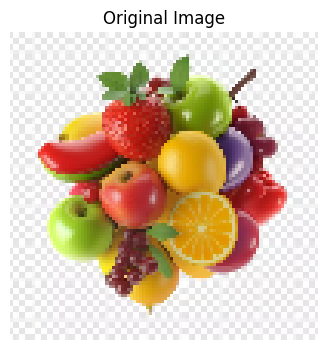

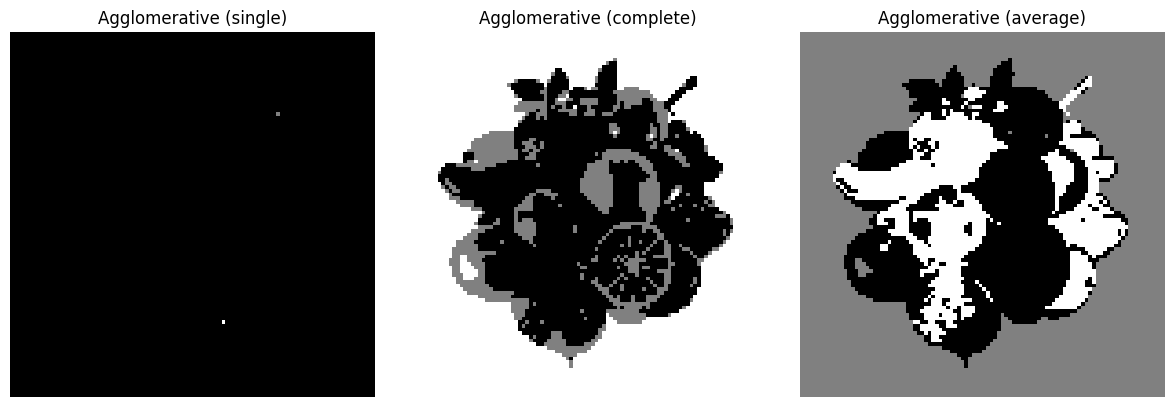

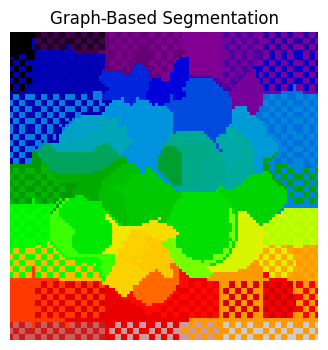

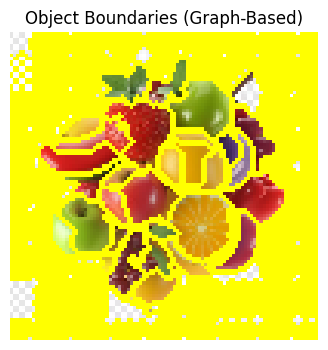

In [7]:

# -------------------------------
# 1. READ AND PREPROCESS IMAGE
# -------------------------------

# CHANGE IMAGE PATH HERE
image_path = "E:\projects\Class_Assignment\image1.jpeg"

img = cv2.imread(image_path)

if img is None:
    raise ValueError("Image not found. Check the image path.")

img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

# Resize image for faster processing
img = cv2.resize(img, (100, 100))

# Show original image
plt.figure(figsize=(4,4))
plt.imshow(img)
plt.title("Original Image")
plt.axis("off")
plt.show()

# -------------------------------
# 2. PREPARE FEATURE VECTORS
# -------------------------------

# Convert image to pixel feature vectors (R,G,B)
pixels = img.reshape((-1, 3))

# -------------------------------
# 3. AGGLOMERATIVE CLUSTERING
# -------------------------------

linkage_methods = ['single', 'complete', 'average']

plt.figure(figsize=(12,4))

for i, linkage in enumerate(linkage_methods):
    
    model = AgglomerativeClustering(
        n_clusters=3,
        linkage=linkage
    )
    
    labels = model.fit_predict(pixels)
    segmented = labels.reshape(img.shape[:2])
    
    plt.subplot(1,3,i+1)
    plt.imshow(segmented, cmap='gray')
    plt.title(f"Agglomerative ({linkage})")
    plt.axis("off")

plt.tight_layout()
plt.show()

# -------------------------------
# 4. GRAPH-BASED CLUSTERING
# -------------------------------

graph_segments = segmentation.felzenszwalb(
    img,
    scale=100,
    sigma=0.5,
    min_size=50
)

plt.figure(figsize=(4,4))
plt.imshow(graph_segments, cmap='nipy_spectral')
plt.title("Graph-Based Segmentation")
plt.axis("off")
plt.show()

# -------------------------------
# 5. OBJECT BOUNDARIES VISUALIZATION
# -------------------------------

boundaries = segmentation.mark_boundaries(img, graph_segments)

plt.figure(figsize=(4,4))
plt.imshow(boundaries)
plt.title("Object Boundaries (Graph-Based)")
plt.axis("off")
plt.show()
